This notebook was (heavily) inspired from [PyTorch Documentation](https://pytorch.org/docs/stable/index.html) and [this post](https://pytorch.org/tutorials/beginner/blitz/autograd_tutorial.html
).

# Numpy to PyTorch

<svg xmlns="http://www.w3.org/2000/svg" width="480" height="200" viewBox="0 0 600 250">
<g transform="translate(10,10) scale(0.4)"><polygon fill="#4DABCF" points="220.93 127.14 151.77 92.23 75.87 130.11 146.9 165.78 220.93 127.14"/><polygon fill="#4DABCF" points="252.63 143.14 325.14 179.74 249.91 217.52 178.77 181.79 252.63 143.14"/><polygon fill="#4DABCF" points="349.47 92.76 423.96 130.11 357.34 163.57 284.68 126.92 349.47 92.76"/><polygon fill="#4DABCF" points="317.41 76.67 250.35 43.05 184.01 76.15 253.11 111 317.41 76.67"/><polygon fill="#4DABCF" points="264.98 365.44 264.98 456.95 346.22 416.41 346.13 324.86 264.98 365.44"/><polygon fill="#4DABCF" points="346.1 292.91 346.01 202.32 264.98 242.6 264.98 333.22 346.1 292.91"/><polygon fill="#4DABCF" points="443.63 275.93 443.63 367.8 374.34 402.38 374.29 310.93 443.63 275.93"/><polygon fill="#4DABCF" points="443.63 243.81 443.63 153.79 374.21 188.3 374.27 279.07 443.63 243.81"/><path fill="#4D77CF" d="M236.3,242.6l-54.72-27.51V334s-66.92-142.39-73.12-155.18c-.8-1.65-4.09-3.46-4.93-3.9-12-6.3-47.16-24.11-47.16-24.11V360.89l48.64,26V277.08s66.21,127.23,66.88,128.62,7.32,14.8,14.42,19.51c9.46,6.26,50,30.64,50,30.64Z"/></g>
<text x="110" y="235" fill="#4D77CF" font-family="Helvetica, Arial, sans-serif" font-size="26" font-weight="bold" text-anchor="middle">NumPy</text>
<g fill="none" stroke="#555555" stroke-width="10" stroke-linecap="round" stroke-linejoin="round">
<path d="M240 110 H350"/><path d="M320 80 L355 110 L320 140"/></g>
<g transform="translate(435,20) scale(1.65) translate(-0.6,-1067.9)"><path fill="#EE4C2C" d="M77.6,1099.6l-8.1,8.1c13.3,13.3,13.3,34.7,0,47.8c-13.3,13.3-34.7,13.3-47.8,0 c-13.3-13.3-13.3-34.7,0-47.8l0,0l21.1-21.1l3-3l0,0v-15.9l-31.8,31.8c-17.7,17.7-17.7,46.3,0,64c17.7,17.7,46.3,17.7,63.7,0 C95.3,1145.8,95.3,1117.4,77.6,1099.6z"/> <circle fill="#EE4C2C" cx="61.7" cy="1091.8" r="5.9"/></g>
<text x="510" y="235" fill="#EE4C2C" font-family="Helvetica, Arial, sans-serif" font-size="26" font-weight="bold" text-anchor="middle">PyTorch</text>
</svg>

[Each question is followed by an empty cell: write your answer there. Use PyTorch for all questions, unless stated otherwise.]

In [1]:
# !pip install torchviz
import matplotlib.pyplot as plt
import numpy as np
import torch
from sklearn.linear_model import LinearRegression
from torch import nn, optim
from torch.utils.data import DataLoader, Dataset, random_split
from torchviz import make_dot


## Introduction to PyTorch

*In this first section, we discover the `torch.Tensor`: it behaves almost exactly like a `np.ndarray`, with two extra super-powers (running on a GPU, and computing its own gradients).*

Create a tensor directly from the python list `[[1, 2], [3, 4]]`, using `torch.tensor`.

In [2]:
data: list[list[int]] = [[1, 2], [3, 4]]
x_data: torch.Tensor = torch.tensor(data)
x_data

tensor([[1, 2],
        [3, 4]])

Create the same tensor, but from a numpy array this time (`np.array`, then `torch.from_numpy`).

In [3]:
np_array: np.ndarray = np.array(data)
x_np: torch.Tensor = torch.from_numpy(np_array)
x_np

tensor([[1, 2],
        [3, 4]])

Create tensors *shaped like* an existing one: one filled with ones, one filled with zeros of `dtype=torch.float`, and one filled with random values.

*Hint: `torch.ones_like`, `torch.zeros_like`, `torch.rand_like`.*

In [4]:
x_ones: torch.Tensor = torch.ones_like(x_data)
x_zeros: torch.Tensor = torch.zeros_like(x_data, dtype=torch.float)
x_rand: torch.Tensor = torch.rand_like(x_data, dtype=torch.float)
x_ones, x_zeros, x_rand

(tensor([[1, 1],
         [1, 1]]),
 tensor([[0., 0.],
         [0., 0.]]),
 tensor([[0.8400, 0.0086],
         [0.5816, 0.7770]]))

Create a random tensor of shape $3 \times 4$ (`torch.rand`), and print its three main attributes: `.shape`, `.dtype` and `.device`.

In [5]:
tensor: torch.Tensor = torch.rand(3, 4)
tensor.shape, tensor.dtype, tensor.device

(torch.Size([3, 4]), torch.float32, device(type='cpu'))

Move your tensor to the GPU (if you have one available), and print its device again.

*Hint: `torch.cuda.is_available()` and `.to("cuda")`.*

In [6]:
if torch.cuda.is_available():
    tensor = tensor.to("cuda")
tensor.device

device(type='cpu')

What happens if you try to add a tensor living on the CPU and a tensor living on the GPU?

In [7]:
cpu_tensor = torch.ones(3, 4)
gpu_tensor = cpu_tensor.to("cuda") if torch.cuda.is_available() else cpu_tensor

try:
    print(cpu_tensor + gpu_tensor)
except RuntimeError as e:
    print("RuntimeError:", e)

# to make it work, both operands must live on the same device
print(cpu_tensor + gpu_tensor.to("cpu"))

tensor([[2., 2., 2., 2.],
        [2., 2., 2., 2.],
        [2., 2., 2., 2.]])
tensor([[2., 2., 2., 2.],
        [2., 2., 2., 2.],
        [2., 2., 2., 2.]])


*Answer:* PyTorch refuses (`RuntimeError: Expected all tensors to be on the same device`). A tensor is a chunk of memory *on a given device*, and the CPU cannot read the GPU's memory: we have to move one of the two operands explicitly, with `.to(...)`. *(If you have no GPU available, both tensors stay on the CPU and the addition simply works.)*

Slicing and assignment work exactly like in numpy. Create a $4 \times 4$ tensor of ones, then set its column $1$ to $0$ and its row $2$ to $-1$. Print the first row, the first column and the last row.

In [8]:
tensor = torch.ones(4, 4)
tensor[:, 1] = 0
tensor[2, :] = -1
print(tensor)

print(f"First row:    {tensor[0]}")
print(f"First column: {tensor[:, 0]}")  # careful, that's a line vector!
print(f"Last row:     {tensor[-1, ...]}")

tensor([[ 1.,  0.,  1.,  1.],
        [ 1.,  0.,  1.,  1.],
        [-1., -1., -1., -1.],
        [ 1.,  0.,  1.,  1.]])
First row:    tensor([1., 0., 1., 1.])
First column: tensor([ 1.,  1., -1.,  1.])
Last row:     tensor([1., 0., 1., 1.])


Concatenate three copies of that tensor, first along `dim=1`, then along `dim=0` (`torch.cat`). What is the shape of each result?

In [9]:
cat_1 = torch.cat([tensor, tensor, tensor], dim=1)
cat_0 = torch.cat([tensor, tensor, tensor], dim=0)
print(cat_1, cat_1.shape)  # 4x12: concatenated along the columns
print(cat_0, cat_0.shape)  # 12x4: concatenated along the rows

tensor([[ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.],
        [ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.],
        [-1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1., -1.],
        [ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.]]) torch.Size([4, 12])
tensor([[ 1.,  0.,  1.,  1.],
        [ 1.,  0.,  1.,  1.],
        [-1., -1., -1., -1.],
        [ 1.,  0.,  1.,  1.],
        [ 1.,  0.,  1.,  1.],
        [ 1.,  0.,  1.,  1.],
        [-1., -1., -1., -1.],
        [ 1.,  0.,  1.,  1.],
        [ 1.,  0.,  1.,  1.],
        [ 1.,  0.,  1.,  1.],
        [-1., -1., -1., -1.],
        [ 1.,  0.,  1.,  1.]]) torch.Size([12, 4])


Compute, on that same tensor:
- the matrix product $t \, t^{T}$, in two ways (`@` and `.matmul`)
- the element-wise product $t * t$, in two ways (`*` and `.mul`)
- the sum of all its elements (`.sum()`)

In [10]:
y1 = tensor @ tensor.T     # matrix product,  4x4
y2 = tensor.matmul(tensor.T)

z1 = tensor * tensor       # element-wise product, 4x4
z2 = tensor.mul(tensor)

print(y1, y2, sep="\n")
print(z1, z2, sep="\n")
print(tensor.sum())

tensor([[ 3.,  3., -3.,  3.],
        [ 3.,  3., -3.,  3.],
        [-3., -3.,  4., -3.],
        [ 3.,  3., -3.,  3.]])
tensor([[ 3.,  3., -3.,  3.],
        [ 3.,  3., -3.,  3.],
        [-3., -3.,  4., -3.],
        [ 3.,  3., -3.,  3.]])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 1., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 1., 1., 1.],
        [1., 0., 1., 1.]])
tensor(5.)


Convert a tensor back to a numpy array (`.numpy()`).

In [11]:
t: torch.Tensor = torch.ones(5)
n: np.ndarray = t.numpy()
t, n, type(n)

(tensor([1., 1., 1., 1., 1.]),
 array([1., 1., 1., 1., 1.], dtype=float32),
 numpy.ndarray)

Everything above is just numpy with extra steps. **The real added value of PyTorch is that a tensor can compute its own gradients.**

Create `a = torch.randn(5)` and `x = torch.randn(5, requires_grad=True)`, then compute $y = \sum_i a_i x_i$ (`torch.sum(a*x)`).

Print `x.grad`: what do you get?

Then call `y.backward()` and print `x.grad` again.

In [12]:
torch.manual_seed(42)
a = torch.randn(5)
x = torch.randn(5, requires_grad=True)
print("a =", a)
print("x =", x)

y = torch.sum(a * x)
print("y =", y)

print("x.grad before backward:", x.grad)  # None: no gradient computed yet
y.backward()
print("x.grad after backward: ", x.grad)

a = tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229])
x = tensor([-0.1863,  2.2082, -0.6380,  0.4617,  0.2674], requires_grad=True)
y = tensor(-0.1217, grad_fn=<SumBackward0>)
x.grad before backward: None
x.grad after backward:  tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229])


Is the gradient you obtained the one you expected? Compute $\frac{\partial y}{\partial x_i}$ by hand and compare.

*Answer:* $y = \sum_i a_i x_i$, so $\frac{\partial y}{\partial x_i} = a_i$: `x.grad` is exactly the tensor `a`. Note also that before `backward()`, `x.grad` is `None` (the gradient does not exist yet), and that `a.grad` stays `None` (we did not ask for its gradient: `requires_grad` is `False`).

Call `y.backward()` a second time. Explain the result obtained.

In [13]:
try:
    y.backward()
except RuntimeError as e:
    print("RuntimeError:", e)

# calling backward() twice works only if we explicitly ask to keep the graph:
y = torch.sum(a * x)
y.backward(retain_graph=True)
y.backward()
print("x.grad =", x.grad)

RuntimeError: Trying to backward through the graph a second time (or directly access saved tensors after they have already been freed). Saved intermediate values of the graph are freed when you call .backward() or autograd.grad(). Specify retain_graph=True if you need to backward through the graph a second time or if you need to access saved tensors after calling backward.
x.grad = tensor([ 1.0101,  0.3864,  0.7034,  0.6910, -3.3686])


*Answer:* To compute a gradient, PyTorch stores the whole computational graph (all the intermediate results of the forward pass). As soon as `backward()` has walked through it, that memory is freed — so a second call has nothing left to walk through. Either recompute `y` (a new forward pass builds a new graph), or ask for the graph to be kept with `y.backward(retain_graph=True)`.

Call `backward()` twice on a freshly recomputed `y`.
What happens to `x.grad`?
What if you use `x.grad.zero_()` in between?

In [14]:
# without zero_(): gradients ACCUMULATE (they are added to .grad, not overwritten)
x = torch.randn(5, requires_grad=True)
y = torch.sum(a * x)
y.backward()
print("after 1 backward:", x.grad)

y = torch.sum(a * x)  # fresh forward pass
y.backward()
print("after 2 backwards:", x.grad)  # twice the gradient!

# with zero_() in between: we get the right gradient again
y = torch.sum(a * x)
x.grad.zero_()
y.backward()
print("after zero_():", x.grad)

after 1 backward: tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229])
after 2 backwards: tensor([ 0.6734,  0.2576,  0.4689,  0.4607, -2.2457])
after zero_(): tensor([ 0.3367,  0.1288,  0.2345,  0.2303, -1.1229])


-----

## Differentiating in three ways

- $f(x) = \frac{x^2}{5}+ \cos x$
- $z(x,y) = \frac{x}{y} + \cos x * \sin y$


We will differentiate $f$ (and then $z$) in three different ways, and check that the three give the same answer.

#### Using symbolic differentiation

Compute $f'$ by hand, then write the two python functions `f(x)` and `df(x)` (with numpy), and plot both on $[-3, 3]$ (use `np.linspace` with $100$ points).

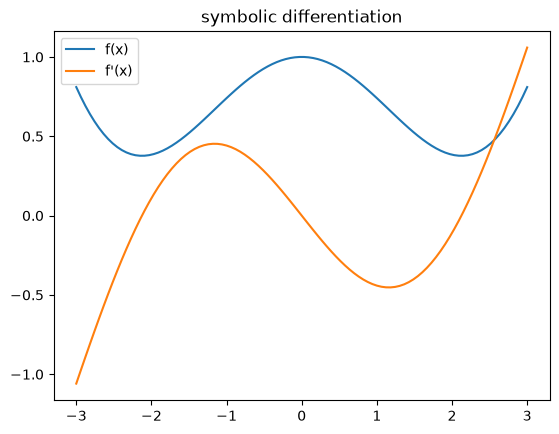

In [15]:
# f(x) = x^2/5 + cos(x)  ->  f'(x) = 2x/5 - sin(x)
def f(x):
    return (x**2)/5 + np.cos(x)

def df(x):
    return 0.4*x - np.sin(x)

x = np.linspace(-3, 3, 100)
plt.plot(x, f(x), label='f(x)')
plt.plot(x, df(x), label="f'(x)")
plt.legend()
plt.title('symbolic differentiation')
plt.show()

#### Using finite differences

Now write `df` *without* knowing the analytical derivative, using the centered finite difference:

$f'(x) \approx \frac{f(x+\epsilon) - f(x-\epsilon)}{2\epsilon}$

with $\epsilon = 10^{-3}$. Plot it on top of the previous one to check they match.

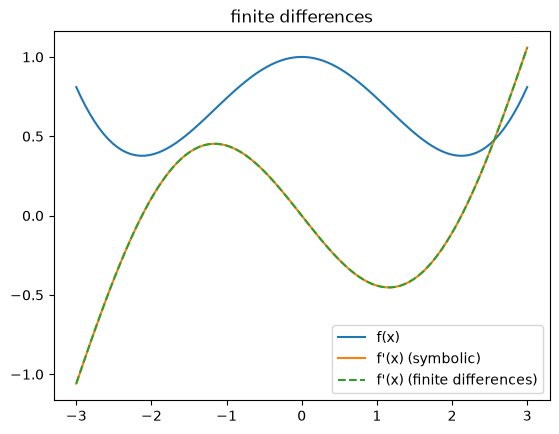

max error: 1.6661319102162508e-07


In [16]:
def df_finite(x, eps=1e-3):
    return (f(x+eps) - f(x-eps)) / (2*eps)

plt.plot(x, f(x), label='f(x)')
plt.plot(x, df(x), label="f'(x) (symbolic)")
plt.plot(x, df_finite(x), '--', label="f'(x) (finite differences)")
plt.legend()
plt.title('finite differences')
plt.show()

# the two derivatives are indistinguishable on the plot:
print('max error:', np.abs(df(x) - df_finite(x)).max())

Try again with a much smaller $\epsilon$ (say $10^{-12}$, then $10^{-20}$). What happens, and why?

eps=1e-03  max error: 1.666e-07
eps=1e-06  max error: 2.060e-10
eps=1e-09  max error: 1.966e-07
eps=1e-12  max error: 2.014e-04
eps=1e-20  max error: 1.059e+00


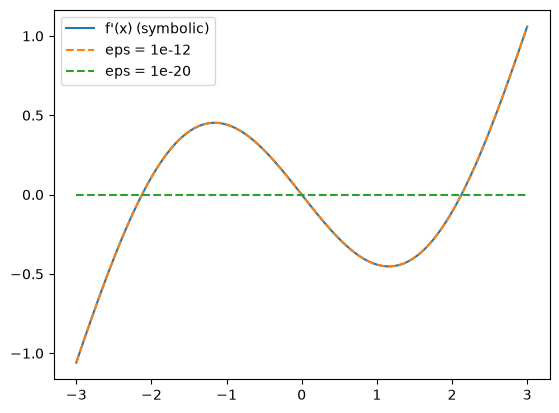

In [17]:
for eps in [1e-3, 1e-6, 1e-9, 1e-12, 1e-20]:
    print(f'eps={eps:.0e}  max error: {np.abs(df(x) - df_finite(x, eps)).max():.3e}')

plt.plot(x, df(x), label="f'(x) (symbolic)")
plt.plot(x, df_finite(x, 1e-12), '--', label="eps = 1e-12")
plt.plot(x, df_finite(x, 1e-20), '--', label="eps = 1e-20")
plt.legend()
plt.show()

*Answer:* Mathematically, the smaller $\epsilon$, the better the approximation; numerically, it is the opposite. $f(x+\epsilon)$ and $f(x-\epsilon)$ are stored with about $16$ significant digits, so subtracting two nearly equal numbers destroys most of them (*catastrophic cancellation*), and we then divide that noise by a tiny $2\epsilon$. For $\epsilon = 10^{-20}$, $x \pm \epsilon$ is rounded back to $x$ in float64: the numerator is exactly $0$, and the derivative is estimated as $0$ everywhere. The best $\epsilon$ is a compromise (around $10^{-5}$–$10^{-8}$ here), which is one reason we do *not* train neural networks with finite differences.

#### Using PyTorch's autograd

Rewrite `f` with torch operations (`torch.cos` instead of `np.cos`), create `x = torch.linspace(-3, 3, 100, requires_grad=True)`, and compute `y = f(x)`.

Call `y.sum().backward()`, and read the derivative in `x.grad`.

*Hint: `backward()` only works on a scalar; summing over the $100$ points is a trick to get all $100$ derivatives at once, since $\frac{\partial}{\partial x_i} \sum_j f(x_j) = f'(x_i)$.*

*Hint: to plot a tensor that requires grad, you need to detach it first: `plt.plot(x.detach(), y.detach())`.*

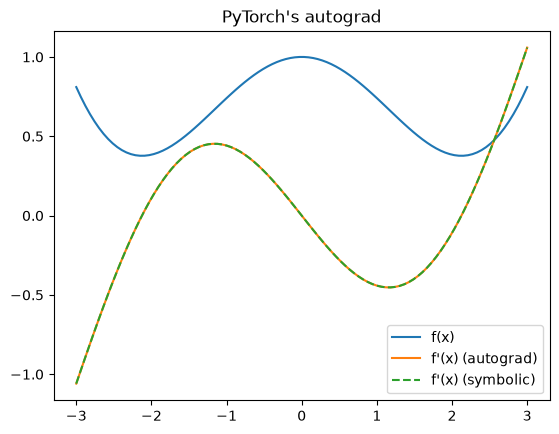

max error: 5.9604645e-08


In [18]:
def f(x):
    return (x**2)/5 + torch.cos(x)  # same function, torch operations

x_t = torch.linspace(-3, 3, 100, requires_grad=True)
y_t = f(x_t)

y_t.sum().backward()  # backward() needs a scalar: we sum over the 100 points

plt.plot(x_t.detach(), y_t.detach(), label='f(x)')
plt.plot(x_t.detach(), x_t.grad, label="f'(x) (autograd)")
plt.plot(x_t.detach(), df(x_t.detach().numpy()), '--', label="f'(x) (symbolic)")
plt.legend()
plt.title("PyTorch's autograd")
plt.show()

print('max error:', np.abs(x_t.grad.numpy() - df(x_t.detach().numpy())).max())

Do the same for $z(x,y) = \frac{x}{y} + \cos x * \sin y$: compute $\frac{\partial z}{\partial x}$ and $\frac{\partial z}{\partial y}$ at a few points with autograd, and check them against the derivatives you compute by hand.

*Hint: this time you have two tensors with `requires_grad=True`; after `backward()`, each of them carries its own `.grad`.*

In [19]:
# z(x, y) = x/y + cos(x) * sin(y)
# dz/dx = 1/y - sin(x) * sin(y)
# dz/dy = -x/y**2 + cos(x) * cos(y)
def z(x, y):
    return x/y + torch.cos(x) * torch.sin(y)

xs_ = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
ys_ = torch.tensor([1.0, 0.5, 2.0], requires_grad=True)

z(xs_, ys_).sum().backward()  # again, sum to get a scalar

print('dz/dx (autograd) :', xs_.grad)
print('dz/dx (by hand)  :', 1/ys_ - torch.sin(xs_) * torch.sin(ys_))
print('dz/dy (autograd) :', ys_.grad)
print('dz/dy (by hand)  :', -xs_/ys_**2 + torch.cos(xs_) * torch.cos(ys_))

dz/dx (autograd) : tensor([0.2919, 1.5641, 0.3717])
dz/dx (by hand)  : tensor([0.2919, 1.5641, 0.3717], grad_fn=<SubBackward0>)
dz/dy (autograd) : tensor([-0.7081, -8.3652, -0.3380])
dz/dy (by hand)  : tensor([-0.7081, -8.3652, -0.3380], grad_fn=<AddBackward0>)


Which of the three methods would you use for a neural network with a million parameters? Why?

*Answer:* Autograd. Symbolic differentiation would mean deriving by hand (or symbolically expanding) an expression with a million variables — unusable, and to be redone at every architecture change. Finite differences need (at least) one extra forward pass *per parameter*, so a million forward passes for a single gradient step, and the result is numerically poor. Autograd gives the exact gradient of *all* the parameters at once, for roughly the cost of one forward pass.

-----

## Torching a linear regression

Here is the linear regression by gradient descent we wrote in numpy last week (compared to the analytical solution of `sklearn`). **Run it**, keep the data (`xs`, `ys`) and the reference values (`skl_a`, `skl_b`): we are going to rewrite this exact same training, step by step, in PyTorch.

Numpy:   [1.02151009] [1.95402174]
SKlearn: [1.02150962] [1.95402268]


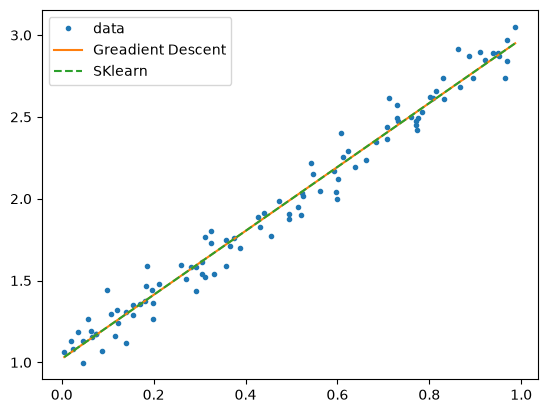

In [20]:
# Data Generation
np.random.seed(42)
xs = np.random.rand(100, 1)
ys = 1 + 2 * xs + .1 * np.random.randn(100, 1)
plt.plot(xs, ys, '.', label='data')

np.random.seed(42)
a = np.random.randn(1)  # a + b * xs
b = np.random.randn(1)  # a + b * xs

lr = 1e-1
n_epochs = 1000
for epoch in range(n_epochs):
    # compute our model's predicted output
    yhat = a + b * xs
    
    # compute the error
    error = (ys - yhat)
    # compute the loss (MSE)
    loss = (error ** 2).mean()
    
    # compute gradients for both a and b parameters
    a_grad = -2 * error.mean()
    b_grad = -2 * (xs * error).mean()
    
    # update parameters using gradients and the learning rate
    a = a - lr * a_grad
    b = b - lr * b_grad
print('Numpy:  ', a, b)
plt.plot([np.min(xs), np.max(xs)], [a+np.min(xs)*b,a+np.max(xs)*b], "-", label='Greadient Descent')


linr = LinearRegression()
linr.fit(xs, ys)
skl_a = linr.intercept_
skl_b = linr.coef_[0]
plt.plot([np.min(xs), np.max(xs)], [skl_a+np.min(xs)*skl_b,skl_a+np.max(xs)*skl_b], "--", label='SKlearn')
plt.legend()
plt.plot()

print('SKlearn:', skl_a, skl_b)

First, define the best device available (`'cuda'` if a GPU is available, `'cpu'` otherwise).

In [21]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cpu'

Transform the numpy arrays `xs` and `ys` into torch tensors of type `float`, and send them to that device.

*Hint: `torch.from_numpy(...).float().to(device)`.*

Print `type(xs)`, `type(xs_tensor)` and `xs_tensor.type()` to see the difference.

In [22]:
xs_tensor = torch.from_numpy(xs).float().to(device)
ys_tensor = torch.from_numpy(ys).float().to(device)

type(xs), type(xs_tensor), xs_tensor.type()

(numpy.ndarray, torch.Tensor, 'torch.FloatTensor')

Initialize the parameters $a$ and $b$ randomly (`torch.randn`). Since we want to apply gradient descent on them, do not forget `requires_grad=True` (and `dtype=torch.float`, `device=device`).

*Use `torch.manual_seed(42)` so that your results are reproducible.*

In [23]:
torch.manual_seed(42)
a = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
b = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
a, b

(tensor([0.3367], requires_grad=True), tensor([0.1288], requires_grad=True))

Rewrite the main gradient descent loop ($1000$ epochs, $lr = 0.1$), but let PyTorch compute the gradients for you:
- compute `yhat`, `error` and `loss` exactly as before
- use `loss.backward()` to get the gradients instead of writing `a_grad` and `b_grad` by hand
- update the parameters inside a `with torch.no_grad():` block (otherwise PyTorch tries to track the update itself, and complains)
- use `.zero_()` on the gradients of $a$ and $b$ after each update

Print your final $a$ and $b$, and compare them with `skl_a` and `skl_b`.

In [24]:
lr = 1e-1
n_epochs = 1000

torch.manual_seed(42)
a = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
b = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)

for epoch in range(n_epochs):
    # compute our model's predicted output
    yhat = a + b * xs_tensor
    # compute the error
    error = ys_tensor - yhat
    # compute the loss (MSE)
    loss = (error ** 2).mean()

    # compute the gradients of a and b: PyTorch does it for us
    loss.backward()

    # update parameters using gradients and the learning rate;
    # no_grad() because this update is NOT part of the model's computation
    with torch.no_grad():
        a -= lr * a.grad
        b -= lr * b.grad

    # reset the gradients, otherwise they would accumulate over the epochs
    a.grad.zero_()
    b.grad.zero_()

print('Torch:  ', a.item(), b.item())
print('SKlearn:', skl_a.item(), skl_b.item())

Torch:   1.0215120315551758 1.9540181159973145
SKlearn: 1.0215096157546748 1.954022677287697


-----
### Interlude: digging into PyTorch's internal system

We will try to understand this part of the code:
```
torch.manual_seed(42)
a = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
b = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
yhat = a + b * xs_tensor
error = ys_tensor - yhat
loss = (error ** 2).mean()
```
Run it (outside of any loop), then use the `make_dot()` function on `yhat` to see the computational graph PyTorch constructed to get `yhat`.

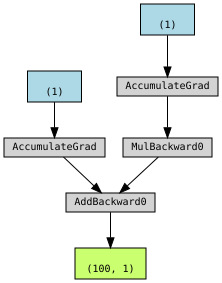

In [25]:
torch.manual_seed(42)
a = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
b = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
yhat = a + b * xs_tensor
error = ys_tensor - yhat
loss = (error ** 2).mean()

make_dot(yhat)

Use `make_dot()` again, on `error` and on `loss`. Watch the graph grow as operations are chained: this graph is exactly what `backward()` walks through, and what gets freed after it.

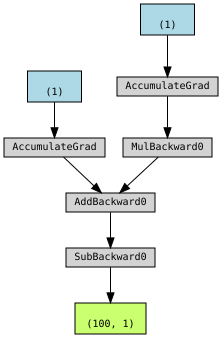

In [26]:
make_dot(error)

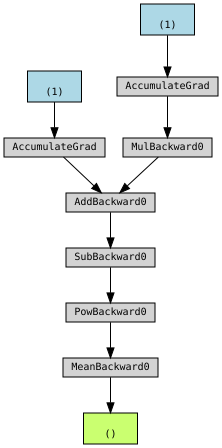

In [27]:
make_dot(loss)

What if we did not need the gradient of $a$? Rebuild `yhat` with `a` created with `requires_grad=False`, and plot the computational graph again. What changed?

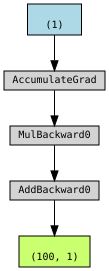

In [28]:
torch.manual_seed(42)
a_nograd = torch.randn(1, requires_grad=False, dtype=torch.float, device=device)
b = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
yhat = a_nograd + b * xs_tensor

# the branch of the graph that led to "a" is gone: there is no AccumulateGrad
# node for it anymore, since PyTorch does not need its gradient
make_dot(yhat)

The graph is built *at runtime*, which means it can depend on python control flow. Add an `if` condition to your loss, for instance:
```
if loss > 0:
    yhat2 = b * xs_tensor
    error2 = ys_tensor - yhat2
loss += error2.mean()
```
and plot the resulting graph.

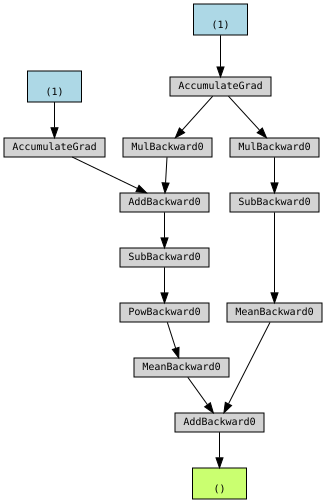

In [29]:
torch.manual_seed(42)
a = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
b = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
yhat = a + b * xs_tensor
error = ys_tensor - yhat
loss = (error ** 2).mean()

if loss > 0:
    yhat2 = b * xs_tensor
    error2 = ys_tensor - yhat2
loss += error2.mean()

# the graph now contains the operations of the branch that was actually
# executed: it is built at runtime, and could be different at the next epoch
make_dot(loss)

-----

Getting back to the main gradient descent loop: rewrite it using an **optimizer** instead of updating the parameters by hand (use `optim.SGD([a, b], lr=lr)`).

*Hint: `optimizer.step()` replaces the `with torch.no_grad(): a -= ...`, and `optimizer.zero_grad()` replaces the two `.zero_()`.*

In [30]:
lr = 1e-1
n_epochs = 1000

torch.manual_seed(42)
a = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
b = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)

optimizer = optim.SGD([a, b], lr=lr)

for epoch in range(n_epochs):
    yhat = a + b * xs_tensor
    error = ys_tensor - yhat
    loss = (error ** 2).mean()
    loss.backward()

    optimizer.step()       # replaces the manual update
    optimizer.zero_grad()  # replaces a.grad.zero_() / b.grad.zero_()

print('Torch:  ', a.item(), b.item())
print('SKlearn:', skl_a.item(), skl_b.item())

Torch:   1.0215120315551758 1.9540181159973145
SKlearn: 1.0215096157546748 1.954022677287697


Rewrite the loop again, using PyTorch's MSE (`nn.MSELoss(reduction='mean')`) instead of computing the loss yourself.

In [31]:
lr = 1e-1
n_epochs = 1000

torch.manual_seed(42)
a = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)
b = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)

loss_fn = nn.MSELoss(reduction='mean')
optimizer = optim.SGD([a, b], lr=lr)

for epoch in range(n_epochs):
    yhat = a + b * xs_tensor
    loss = loss_fn(yhat, ys_tensor)  # replaces ((ys_tensor - yhat)**2).mean()
    loss.backward()

    optimizer.step()
    optimizer.zero_grad()

print('Torch:  ', a.item(), b.item())
print('SKlearn:', skl_a.item(), skl_b.item())

Torch:   1.0215120315551758 1.9540181159973145
SKlearn: 1.0215096157546748 1.954022677287697


Write the linear regression as a `nn.Module` class, and rewrite the training loop using it.

The class must:
- inherit from `nn.Module`, and call `super().__init__()`
- declare $a$ and $b$ as `nn.Parameter(...)` (this is what makes them *real* parameters of the model, visible by `model.parameters()`)
- implement a `forward(self, x)` method returning the prediction

Then build the model with `model = ManualLinearRegression().to(device)`, give `model.parameters()` to the optimizer, and call the model with `model(xs_tensor)`.

At the end, print `dict(model.state_dict())` and compare with `skl_a`, `skl_b`.

In [32]:
class ManualLinearRegression(nn.Module):
    def __init__(self):
        super().__init__()
        # to make "a" and "b" real parameters of the model,
        # we need to wrap them with nn.Parameter
        self.a = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))
        self.b = nn.Parameter(torch.randn(1, requires_grad=True, dtype=torch.float))

    def forward(self, x):
        # computes the outputs / predictions
        return self.a + self.b * x


lr = 1e-1
n_epochs = 1000

torch.manual_seed(42)
model = ManualLinearRegression().to(device)
loss_fn = nn.MSELoss(reduction='mean')
optimizer = optim.SGD(model.parameters(), lr=lr)

for epoch in range(n_epochs):
    model.train()
    yhat = model(xs_tensor)
    loss = loss_fn(yhat, ys_tensor)
    loss.backward()

    optimizer.step()
    optimizer.zero_grad()

print('Torch:  ', dict(model.state_dict()))
print('SKlearn:', skl_a.item(), skl_b.item())

Torch:   {'a': tensor([1.0215]), 'b': tensor([1.9540])}
SKlearn: 1.0215096157546748 1.954022677287697


NB: `model.train()` sets the model to training mode. This is important for models that use mechanisms which have distinct behaviors in training and evaluation phases (we will talk about it later). Add it to your code above as a good practice.

Create a PyTorch `Dataset` to hold your data.

*(This may seem silly since our data is very small, but imagine each piece of data could be an image instead of a pair $(x,y)$: then it would make sense to use such machinery.)*

Write a `CustomDataset(Dataset)` class implementing `__init__(self, x_tensor, y_tensor)`, `__getitem__(self, index)` (returning the pair `(x[index], y[index])`) and `__len__(self)`. Build it and print its first element.

In [33]:
class CustomDataset(Dataset):
    def __init__(self, x_tensor, y_tensor):
        self.x = x_tensor
        self.y = y_tensor

    def __getitem__(self, index):
        return (self.x[index], self.y[index])

    def __len__(self):
        return len(self.x)


# the dataset stays on the cpu: batches are sent to the device one by one
xs_tensor_cpu = torch.from_numpy(xs).float()
ys_tensor_cpu = torch.from_numpy(ys).float()

train_data = CustomDataset(xs_tensor_cpu, ys_tensor_cpu)
print(len(train_data))
train_data[0]

100


(tensor([0.3745]), tensor([1.7578]))

Wrap it in a `DataLoader` with `batch_size=16` and `shuffle=True`, and look at one batch (`next(iter(train_loader))`). What is the shape of what you get?

In [34]:
train_loader = DataLoader(dataset=train_data, batch_size=16, shuffle=True)

x_batch, y_batch = next(iter(train_loader))
x_batch.shape, y_batch.shape  # 16 pairs (x, y), each of shape (1,)

(torch.Size([16, 1]), torch.Size([16, 1]))

Rewrite the training loop using the batches given by the dataloader: for each epoch, iterate over `train_loader`, and do not forget to send each batch to the device (`x_batch.to(device)`).

How many parameter updates are done per epoch now, compared to before?

In [35]:
lr = 1e-1
n_epochs = 1000

torch.manual_seed(42)
model = ManualLinearRegression().to(device)
loss_fn = nn.MSELoss(reduction='mean')
optimizer = optim.SGD(model.parameters(), lr=lr)

for epoch in range(n_epochs):
    for x_batch, y_batch in train_loader:
        # the dataloader gives cpu tensors: send them to the device
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        model.train()
        yhat = model(x_batch)
        loss = loss_fn(yhat, y_batch)
        loss.backward()

        optimizer.step()
        optimizer.zero_grad()

print('Torch:  ', dict(model.state_dict()))
print('SKlearn:', skl_a.item(), skl_b.item())
print('updates per epoch:', len(train_loader))

Torch:   {'a': tensor([1.0265]), 'b': tensor([1.9669])}
SKlearn: 1.0215096157546748 1.954022677287697
updates per epoch: 7


*Answer:* One update per epoch before (the whole dataset was one single batch: *batch gradient descent*), $\lceil 100/16 \rceil = 7$ now — so $7000$ updates instead of $1000$. Each update uses only $16$ points, so its gradient is noisier, but we make many more of them and each one is much cheaper: this is *mini-batch stochastic gradient descent*, and it is what makes training on datasets that do not fit in memory possible at all.

Finally, before training, split your dataset between a training and a testing set ($80\%$ training, $20\%$ testing), using `random_split`. Use one dataloader for each.

Every $1/10$ of the epochs, compute and print the loss on the validation set:
- inside a `with torch.no_grad():` block (no gradient needed, it is not training)
- with the model set to evaluation mode (`model.eval()`, the opposite of `model.train()`)

Does the validation loss look like the training loss? Should it, on this dataset?

In [36]:
lr = 1e-1
n_epochs = 1000

dataset = CustomDataset(xs_tensor_cpu, ys_tensor_cpu)
train_dataset, val_dataset = random_split(dataset, [80, 20])
train_loader = DataLoader(dataset=train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(dataset=val_dataset, batch_size=20)

torch.manual_seed(42)
model = ManualLinearRegression().to(device)
loss_fn = nn.MSELoss(reduction='mean')
optimizer = optim.SGD(model.parameters(), lr=lr)

for epoch in range(n_epochs):
    for x_batch, y_batch in train_loader:
        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        model.train()
        yhat = model(x_batch)
        loss = loss_fn(yhat, y_batch)
        loss.backward()

        optimizer.step()
        optimizer.zero_grad()

    if epoch % (n_epochs // 10) == 0:
        with torch.no_grad():  # no gradient needed: we are not training here
            for x_val, y_val in val_loader:
                x_val = x_val.to(device)
                y_val = y_val.to(device)

                model.eval()  # getting out of the training mode
                yhat = model(x_val)
                val_loss = loss_fn(yhat, y_val)
            print(f'epoch: {epoch}/{n_epochs}; validation loss: {float(val_loss):.5f}')

print('\nTorch:  ', dict(model.state_dict()))
print('SKlearn:', skl_a.item(), skl_b.item())

epoch: 0/1000; validation loss: 0.26206
epoch: 100/1000; validation loss: 0.00487
epoch: 200/1000; validation loss: 0.00496
epoch: 300/1000; validation loss: 0.00486
epoch: 400/1000; validation loss: 0.00498
epoch: 500/1000; validation loss: 0.00485
epoch: 600/1000; validation loss: 0.00503
epoch: 700/1000; validation loss: 0.00486
epoch: 800/1000; validation loss: 0.00487
epoch: 900/1000; validation loss: 0.00487

Torch:   {'a': tensor([1.0203]), 'b': tensor([1.9645])}
SKlearn: 1.0215096157546748 1.954022677287697


*Answer:* Yes, and here it should: both sets are drawn from the same $y = 1 + 2x + \epsilon$, and our model has $2$ parameters for $80$ training points — there is nothing to overfit, so the validation loss stays of the same order as the training loss, both driven by the noise we added ($\approx 0.1^2 = 0.01$; the exact value wanders — with only $20$ validation points, it is a noisy estimate). The day the model has enough capacity to learn the noise (a real neural network), the two curves separate — and *that* gap is what the validation set is for.

-----

## Torching the $XOR$ network

Here is the 2-layer neural network fitting the $XOR$ function that we wrote (entirely by hand) in numpy in Course02. **Run it**, keep the data (`xs_xor`, `ys_xor`): we are going to rewrite this exact same network in PyTorch, and watch the backward pass disappear.

Notice how much of that code is the backward pass: every gradient had to be derived by hand, and a single wrong transpose silently breaks the training.

numpy outputs: [1.33226763e-15 1.00000000e+00 1.00000000e+00 2.22044605e-15]


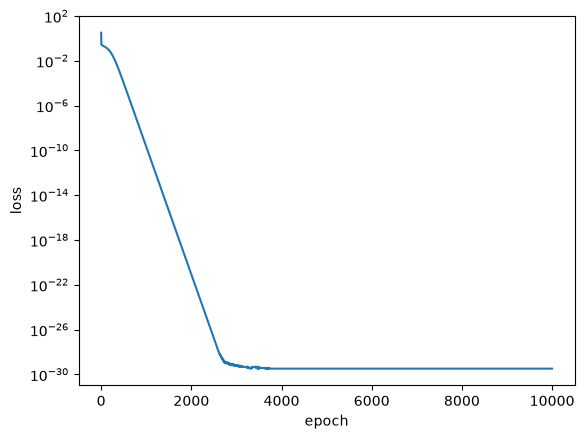

In [37]:
def xor(a, b):
    return not (a == b == 1 or a == b == 0)

xs_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
ys_xor = np.array([[float(xor(a, b))] for a, b in xs_xor])

n_hidden = 10
lr = 0.2
n_epochs = 10_000

np.random.seed(42)
w1 = np.random.randn(2, n_hidden)
b1 = np.random.randn(n_hidden)
w2 = np.random.randn(n_hidden, 1)
b2 = np.random.randn(1)

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def dsigmoid(x):
    return sigmoid(x) * (1 - sigmoid(x))

def forward_pass(x):
    return sigmoid(x @ w1 + b1) @ w2 + b2

losses = []
for epoch in range(n_epochs):
    # forward pass
    pre_l1 = xs_xor @ w1 + b1
    l1 = sigmoid(pre_l1)
    out = l1 @ w2 + b2
    loss = ((out - ys_xor) ** 2).mean()

    # backward pass, written by hand
    out_grad = 2 * (out - ys_xor) / len(xs_xor)
    w2_grad = l1.T @ out_grad
    b2_grad = out_grad.sum(axis=0)
    l1_grad = out_grad @ w2.T
    pre_l1_grad = l1_grad * dsigmoid(pre_l1)
    w1_grad = xs_xor.T @ pre_l1_grad
    b1_grad = pre_l1_grad.sum(axis=0)

    # update
    w1 = w1 - lr * w1_grad
    b1 = b1 - lr * b1_grad
    w2 = w2 - lr * w2_grad
    b2 = b2 - lr * b2_grad
    losses.append(loss)

print('numpy outputs:', forward_pass(xs_xor).ravel())
plt.semilogy(losses)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

Transform `xs_xor` and `ys_xor` into torch tensors of type `float`, sent to `device`.

*Hint: same as before, `torch.from_numpy(...).float().to(device)`.*

In [38]:
xs_xor_tensor = torch.from_numpy(xs_xor).float().to(device)
ys_xor_tensor = torch.from_numpy(ys_xor).float().to(device)

xs_xor_tensor, ys_xor_tensor

(tensor([[0., 0.],
         [0., 1.],
         [1., 0.],
         [1., 1.]]),
 tensor([[0.],
         [1.],
         [1.],
         [0.]]))

Rewrite the network with raw tensors, as close as possible to the numpy version:
- create `w1`, `b1`, `w2`, `b2` with `torch.randn(..., requires_grad=True, dtype=torch.float, device=device)` (same shapes as in numpy)
- write `forward_pass(x)` using `torch.sigmoid`
- train for $10000$ epochs with $lr = 0.2$: forward pass, MSE loss, `loss.backward()`, then update every parameter inside a `with torch.no_grad():` block and zero its gradient

Do not write any backward pass: `loss.backward()` replaces all of it.

Plot the losses in a semilogy, and print the network's outputs on the four inputs.

torch outputs: tensor([5.6624e-07, 1.0000e+00, 1.0000e+00, 1.2815e-06])


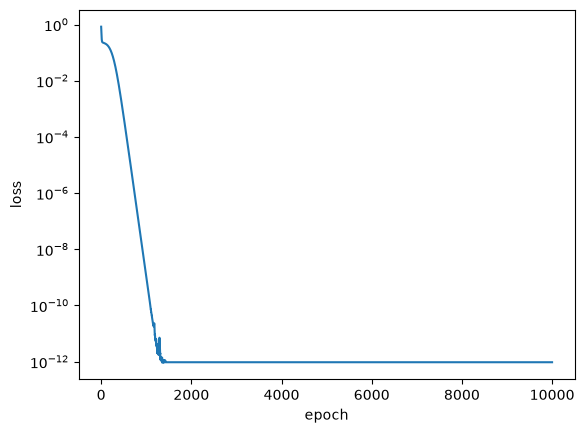

In [39]:
n_hidden = 10
lr = 0.2
n_epochs = 10_000

torch.manual_seed(42)
w1 = torch.randn(2, n_hidden, requires_grad=True, dtype=torch.float, device=device)
b1 = torch.randn(n_hidden, requires_grad=True, dtype=torch.float, device=device)
w2 = torch.randn(n_hidden, 1, requires_grad=True, dtype=torch.float, device=device)
b2 = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)

def forward_pass(x):
    l1 = torch.sigmoid(x @ w1 + b1)
    return l1 @ w2 + b2

losses = []
for epoch in range(n_epochs):
    out = forward_pass(xs_xor_tensor)
    loss = ((out - ys_xor_tensor) ** 2).mean()
    loss.backward()  # this single line replaces the whole backward pass

    with torch.no_grad():
        for p in (w1, b1, w2, b2):
            p -= lr * p.grad
            p.grad.zero_()
    losses.append(loss.item())

print('torch outputs:', forward_pass(xs_xor_tensor).detach().ravel())
plt.semilogy(losses)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

Rewrite the same training loop using `nn.MSELoss(reduction='mean')` and `optim.SGD([w1, b1, w2, b2], lr=lr)` instead of the manual loss and the manual update.

torch outputs: tensor([5.6624e-07, 1.0000e+00, 1.0000e+00, 1.2815e-06])


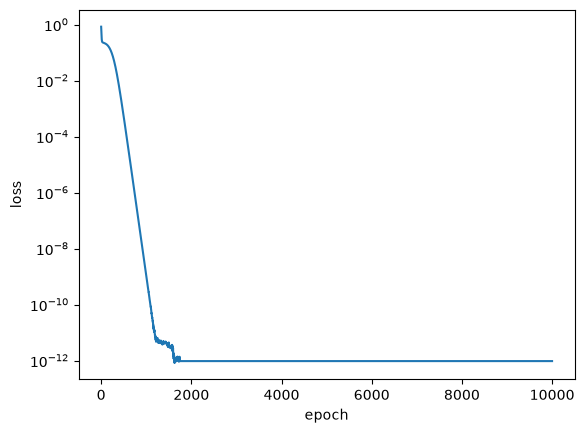

In [40]:
torch.manual_seed(42)
w1 = torch.randn(2, n_hidden, requires_grad=True, dtype=torch.float, device=device)
b1 = torch.randn(n_hidden, requires_grad=True, dtype=torch.float, device=device)
w2 = torch.randn(n_hidden, 1, requires_grad=True, dtype=torch.float, device=device)
b2 = torch.randn(1, requires_grad=True, dtype=torch.float, device=device)

loss_fn = nn.MSELoss(reduction='mean')
optimizer = optim.SGD([w1, b1, w2, b2], lr=lr)

losses = []
for epoch in range(n_epochs):
    out = forward_pass(xs_xor_tensor)
    loss = loss_fn(out, ys_xor_tensor)
    loss.backward()

    optimizer.step()
    optimizer.zero_grad()
    losses.append(loss.item())

print('torch outputs:', forward_pass(xs_xor_tensor).detach().ravel())
plt.semilogy(losses)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

A layer $l_n = l_{n-1}W_n + b_n$ is exactly what `nn.Linear` does. Write the network as a `nn.Module` class `XORNet`:
- `__init__` declares `self.layer1 = nn.Linear(2, n_hidden)` and `self.layer2 = nn.Linear(n_hidden, 1)` (each one carries its own weight matrix *and* bias, already initialized)
- `forward(self, x)` applies `layer1`, then `torch.sigmoid`, then `layer2`

Train it exactly as before, with `optim.SGD(model.parameters(), lr=lr)`.

Print the model, and its outputs on the four inputs: are they close to `ys_xor`?

XORNet(
  (layer1): Linear(in_features=2, out_features=10, bias=True)
  (layer2): Linear(in_features=10, out_features=1, bias=True)
)
torch outputs: tensor([1.0617e-06, 1.0000e+00, 1.0000e+00, 2.1644e-06])
expected:      tensor([0., 1., 1., 0.])


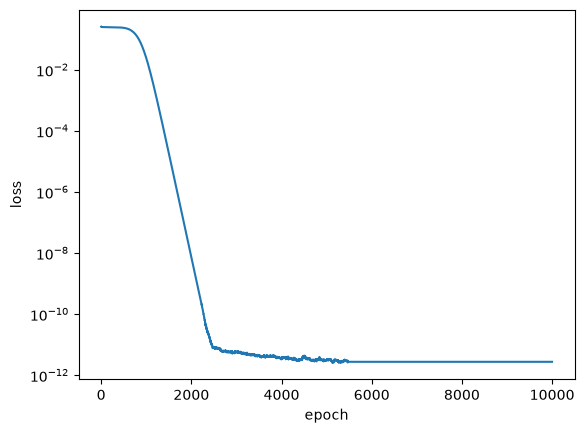

In [41]:
class XORNet(nn.Module):
    def __init__(self, n_hidden=10):
        super().__init__()
        # nn.Linear(in, out) holds both the weight matrix and the bias
        self.layer1 = nn.Linear(2, n_hidden)
        self.layer2 = nn.Linear(n_hidden, 1)

    def forward(self, x):
        l1 = torch.sigmoid(self.layer1(x))
        return self.layer2(l1)


torch.manual_seed(42)
model = XORNet(n_hidden).to(device)
loss_fn = nn.MSELoss(reduction='mean')
optimizer = optim.SGD(model.parameters(), lr=lr)

losses = []
for epoch in range(n_epochs):
    model.train()
    yhat = model(xs_xor_tensor)
    loss = loss_fn(yhat, ys_xor_tensor)
    loss.backward()

    optimizer.step()
    optimizer.zero_grad()
    losses.append(loss.item())

print(model)
print('torch outputs:', model(xs_xor_tensor).detach().ravel())
print('expected:     ', ys_xor_tensor.ravel())
plt.semilogy(losses)
plt.xlabel('epoch')
plt.ylabel('loss')
plt.show()

Since the network is just a stack of layers applied one after the other, it can be written in one go with `nn.Sequential(nn.Linear(2, n_hidden), nn.Sigmoid(), nn.Linear(n_hidden, 1))`.
Do it, and train it.

We went from $\approx 40$ lines of numpy to $3$ lines of model definition: the mathematics has not changed at all, PyTorch just writes the derivatives (and the layers) for us.

In [42]:
torch.manual_seed(42)
model = nn.Sequential(
    nn.Linear(2, n_hidden),
    nn.Sigmoid(),
    nn.Linear(n_hidden, 1),
).to(device)

loss_fn = nn.MSELoss(reduction='mean')
optimizer = optim.SGD(model.parameters(), lr=lr)

for epoch in range(n_epochs):
    model.train()
    loss = loss_fn(model(xs_xor_tensor), ys_xor_tensor)
    loss.backward()

    optimizer.step()
    optimizer.zero_grad()

print('torch outputs:', model(xs_xor_tensor).detach().ravel())

torch outputs: tensor([1.0617e-06, 1.0000e+00, 1.0000e+00, 2.1644e-06])


Replace the hidden $Sigmoid$ by a $ReLU$ (`nn.ReLU()`, with $lr = 0.01$), and plot both losses on the same semilogy.
Which one converges the fastest?

sigmoid outputs: tensor([1.0617e-06, 1.0000e+00, 1.0000e+00, 2.1644e-06])
relu outputs:    tensor([6.8247e-06, 9.9999e-01, 1.0000e+00, 3.8594e-06])


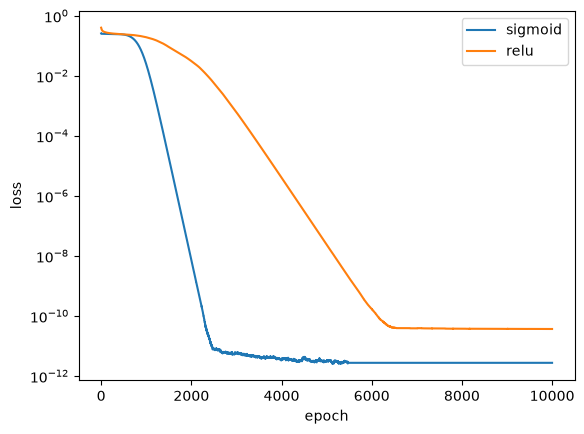

In [43]:
def train_xor(activation, lr, n_epochs=10_000, seed=42, output_activation=None):
    """Build a 2-layer XOR network with the given hidden activation, train it, return the losses."""
    torch.manual_seed(seed)
    layers = [nn.Linear(2, n_hidden), activation, nn.Linear(n_hidden, 1)]
    if output_activation is not None:
        layers.append(output_activation)
    model = nn.Sequential(*layers).to(device)

    loss_fn = nn.MSELoss(reduction='mean')
    optimizer = optim.SGD(model.parameters(), lr=lr)

    losses = []
    for epoch in range(n_epochs):
        model.train()
        loss = loss_fn(model(xs_xor_tensor), ys_xor_tensor)
        loss.backward()

        optimizer.step()
        optimizer.zero_grad()
        losses.append(loss.item())
    return model, losses


model_sig, losses_sig = train_xor(nn.Sigmoid(), lr=0.2)
model_relu, losses_relu = train_xor(nn.ReLU(), lr=0.01)

print('sigmoid outputs:', model_sig(xs_xor_tensor).detach().ravel())
print('relu outputs:   ', model_relu(xs_xor_tensor).detach().ravel())

plt.semilogy(losses_sig, label='sigmoid')
plt.semilogy(losses_relu, label='relu')
plt.xlabel('epoch')
plt.ylabel('loss')
plt.legend()
plt.show()